# 1 · Two kinds of wrong

The navigation chain's telemetry under a physical fault and under false data injection at four
levels. See [Lesson 1](../docs/lessons/01-two-kinds-of-wrong.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

In [2]:
from fdicps.dual_anomaly_data_generation.scenarios import make_scenario

seed = 42
cases = [("normal", None), ("fault", None), ("fdi", 0), ("fdi", 1), ("fdi", 2), ("fdi", 3)]
scenarios = [make_scenario(seed, label, level=level) for label, level in cases]
for s in scenarios:
    print(f"{s.label:6s} {s.subtype:22s} onset {s.onset:4d}")

normal normal                 onset   -1
fault  ins_2 stuck            onset  107
fdi    L0 replace h           onset  107
fdi    L1 offset h            onset  107
fdi    L2 offset h            onset  107
fdi    L3 drag h              onset  107


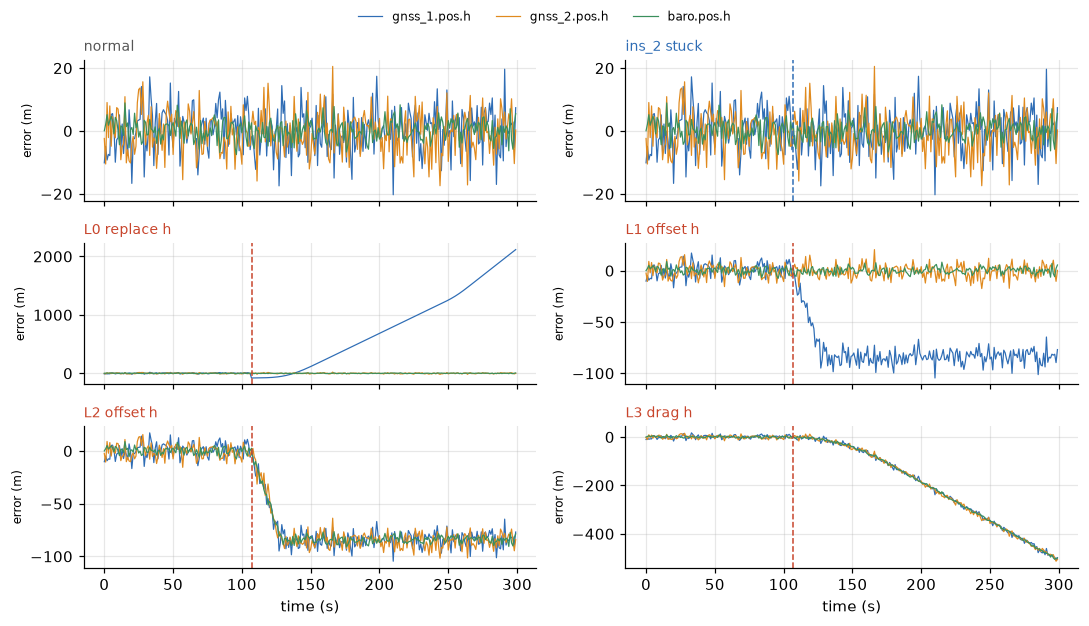

In [3]:
names = ["gnss_1.pos.h", "gnss_2.pos.h", "baro.pos.h"]
fig = plotting.signature_grid(scenarios, names, [s.subtype for s in scenarios], "error (m)")

An L2 injection lies in the range of $H$: the WLS residual does not move.

In [4]:
from fdicps.cross_sensor_consistency_model.navigation import snapshot_models
from fdicps.dual_anomaly_data_generation.fdi import injection

l2 = scenarios[4].anomaly
idx, wls = snapshot_models(P)[l2.axis]
a = injection(l2, P, P.n_steps)[:, idx]
print("largest injected value (m):", np.abs(a).max().round(1))
print("largest residual change:", np.abs(a @ wls.S.T).max())

largest injected value (m): 84.3
largest residual change: 6.496938600077488e-15
